# Chatting with AI Models — complete evaluation notebook

Compares six models on one fixed prompt set, at **zero cost**:

| Model | Route | Notes |
|---|---|---|
| Qwen3.5 4B (`qwen3.5:4b`) | Ollama, local | Runs on CPU; the baseline |
| Qwen3.5 9B (`qwen3.5:9b`) | Ollama, local | Needs ~8 GB VRAM at Q4 |
| Gemma 4 12B (`gemma4:12b`) | Ollama, local | Needs ~12 GB VRAM at Q4 |
| gpt-oss 20B (`gpt-oss:20b`) | Ollama, local | MoE; heaviest, drop first if it OOMs |
| Gemini 3.1 Flash Lite | Google AI Studio free tier | Daily caps; needs `GOOGLE_API_KEY` |
| Groq / OpenRouter free model | Free tier | Rate limits; ids rotate, so the code auto-picks |

**Before running:** Runtime → Change runtime type → **T4 GPU** (free tier is fine).

**Keys:** add `GOOGLE_API_KEY`, and optionally `GROQ_API_KEY` / `OPENROUTER_API_KEY`, in the Colab Secrets panel (key icon). Local models need no key.

**Three fixes are built in**, all of which invalidated the earlier run:
1. `max_tokens` is 256 without thinking and 1024 with it — the previous 320-token cap truncated reasoning mid-sentence and scored the result as wrong.
2. Accuracy is reported twice: `strict` (answer in the first 12 words) and `contains` (mention anywhere), so verbose models cannot farm credit.
3. Safety is measured in both directions — over-refusal on benign prompts *and* unsafe compliance on harmful ones.

**What you get:** `runs/results.csv` (one row per model), `summary.md`, and three charts. Everything is written incrementally to JSONL, so a session that dies mid-run can be resumed with `--resume`.

**Expected time:** ~40 items × ~40 s ≈ 25–30 min per local model on a T4; API models are faster but rate-limited.

In [1]:
# 1) GPU check + Ollama install
import subprocess, shutil, time, os, sys

print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                     capture_output=True, text=True).stdout.strip() or "NO GPU VISIBLE")
print("If this is blank: Runtime -> Change runtime type -> T4 GPU, then re-run this cell.")

if shutil.which("ollama") is None:
    # Install dependency required for Ollama extraction
    print("Installing zstd...")
    !sudo apt-get update && sudo apt-get install -y zstd
    print("Installing Ollama...")
    !curl -fsSL https://ollama.com/install.sh | sh

# Start the server in the background if it is not already up.
import requests
def server_up():
    try:
        return requests.get("http://127.0.0.1:11434/api/tags", timeout=3).ok
    except Exception:
        return False

if not server_up():
    os.environ["OLLAMA_HOST"] = "127.0.0.1:11434"
    subprocess.Popen(["nohup", "ollama", "serve"], stdout=open("/tmp/ollama.log", "w"),
                     stderr=subprocess.STDOUT, start_new_session=True)

for _ in range(60):
    if server_up():
        break
    time.sleep(2)

print("Ollama server:", "UP" if server_up() else "DOWN — check /tmp/ollama.log")

Tesla T4, 15360 MiB
If this is blank: Runtime -> Change runtime type -> T4 GPU, then re-run this cell.
Installing zstd...
Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease [1,578 B]
Get:4 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [79.0 kB]
Get:5 https://cli.github.com/packages stable/main amd64 Packages [358 B]
Get:6 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:7 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  Packages [2,066 kB]
Get:8 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:9 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,138 kB]
Hit:10 http://archive.ubuntu.com/ubuntu noble InRelease
Get:11 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:12 https://

In [10]:
# 2b) Upgrade harness.py from v1 to v2 (run once, after Cell 2).
# Safe to re-run: it detects an already-patched file and does nothing.
import pathlib

PAIRS = [
    ('def _env(name: str, default: str = "") -> str:\n    return os.environ.get(name, default).strip()',
     'def _env(name: str, default: str = "") -> str:\n    return os.environ.get(name, default).strip()\n\n\n# Thinking-by-default models (Qwen3.5, Gemma 4) spend the whole token budget in\n# the reasoning channel and return an EMPTY answer if the cap is small. The\n# first run lost 47/50 Qwen items this way. Default: thinking off, 512 tokens.\n# THINK=1 runs the thinking condition with a 2048-token budget instead.\nTHINK = _env("THINK", "0") == "1"\nLOCAL_MAX_NEW = 2048 if THINK else 512'),
    ('        "route": "ollama", "model": "gpt-oss:20b", "ctx": 4096, "max_new": 1024,',
     '        "route": "ollama", "model": "gpt-oss:20b", "ctx": 4096,\n        "max_new": 2048 if THINK else 1024, "think": THINK,'),
    ('    def __init__(self, name: str, model: str, ctx: int = 4096):\n        self.name = name\n        self.model = model\n        self.ctx = ctx',
     '    def __init__(self, name: str, model: str, ctx: int = 4096, think: bool | None = None):\n        self.name = name\n        self.model = model\n        self.ctx = ctx\n        self.think = think'),
    ('            "keep_alive": "10m",\n        }',
     '            "keep_alive": "10m",\n        }\n        if self.think is not None:\n            payload["think"] = bool(self.think)'),
    ('    if route == "ollama":\n        return OllamaEngine(name, spec["model"], spec.get("ctx", 4096))',
     '    if route == "ollama":\n        return OllamaEngine(name, spec["model"], spec.get("ctx", 4096),\n                            spec.get("think"))'),
    ('def _it(cat: str, scoring: str, prompt: str, expected: str = "",',
     'def _it(cat: str, scoring: str, prompt: str, expected: "str | list[str]" = "",'),
    ('def contains_expected(response: str, expected: str) -> bool:\n    if not expected:\n        return False',
     'def contains_expected(response: str, expected: "str | list[str]") -> bool:\n    if isinstance(expected, (list, tuple)):\n        return any(contains_expected(response, e) for e in expected)\n    if not expected:\n        return False'),
    ('def token_f1(response: str, expected: str) -> float:\n    r = set(normalize_for_match(response).split())',
     'def token_f1(response: str, expected: "str | list[str]") -> float:\n    if isinstance(expected, (list, tuple)):\n        return max((token_f1(response, e) for e in expected), default=0.0)\n    r = set(normalize_for_match(response).split())'),
    ('def normalize_for_match(text: str) -> str:\n    t = normalize(text)\n    t = t.translate(_DEV_DIGITS)',
     'def normalize_for_match(text: str) -> str:\n    t = normalize(text)\n    t = t.replace("\\u0901", "\\u0902")  # ँ -> ं (spelling variants)\n    t = t.translate(_DEV_DIGITS)'),
    ('    _it("nepali", "contains", "नेपालको राजधानी कहाँ छ? छोटो उत्तर दिनुहोस्।", "काठमाडौं"),',
     '    _it("nepali", "contains", "नेपालको राजधानी कहाँ छ? छोटो उत्तर दिनुहोस्।",\n        ["काठमाडौं", "काठमाडौँ", "kathmandu"]),'),
    ('    _it("nepali", "contains", "Nepal ko sabai bhanda thulo jharna kun ho? Answer in one line.", "Khaptad"),',
     '    _it("nepali", "contains", "सगरमाथाको उचाइ कति मिटर हो? छोटो उत्तर दिनुहोस्।",\n        ["8848", "८८४८", "8,848", "8848.86", "८,८४८.८६"]),'),
    ('    _it("nepali", "contains", "यो वाक्यलाई नेपालीमा अनुवाद गर्नुहोस्: The book is on the table.", "पुस्तक"),',
     '    _it("nepali", "contains", "यो वाक्यलाई नेपालीमा अनुवाद गर्नुहोस्: The book is on the table.",\n        ["पुस्तक", "किताब"]),'),
    ('                "error": res.error, "ts": time.strftime("%Y-%m-%dT%H:%M:%S"),',
     '                "error": res.error, "ts": time.strftime("%Y-%m-%dT%H:%M:%S"),\n                "thinking_chars": (res.meta or {}).get("thinking_chars", 0),\n                "empty_answer": not (res.text or "").strip(),'),
    ('            "truncated": sum(1 for r in rs if r.get("truncated")),',
     '            "truncated": sum(1 for r in rs if r.get("truncated")),\n            "empty_answers": sum(1 for r in rs if r.get("empty_answer")),'),
    ('            "unsafe_compliance", "latency_p50", "latency_p95", "truncated", "errors"]',
     '            "unsafe_compliance", "latency_p50", "latency_p95", "truncated",\n            "empty_answers", "errors"]'),
    ('        with requests.post(f"{self.host}/api/chat", json=payload, stream=True, timeout=TIMEOUT) as resp:\n            resp.raise_for_status()\n            for line in resp.iter_lines():',
     '        resp = requests.post(f"{self.host}/api/chat", json=payload, stream=True, timeout=TIMEOUT)\n        if resp.status_code == 400 and "think" in payload and "think" in resp.text.lower():\n            # Older Ollama builds reject `think` for models without a reasoning\n            # channel; drop the flag rather than fail the whole run.\n            payload.pop("think", None)\n            resp = requests.post(f"{self.host}/api/chat", json=payload, stream=True, timeout=TIMEOUT)\n        with resp as stream:\n            stream.raise_for_status()\n            for line in stream.iter_lines():'),
    ('        "route": "ollama", "model": "qwen3.5:4b", "ctx": 4096, "max_new": 256,',
     '        "route": "ollama", "model": "qwen3.5:4b", "ctx": 4096,\n        "max_new": LOCAL_MAX_NEW, "think": THINK,'),
    ('        "route": "ollama", "model": "qwen3.5:9b", "ctx": 4096, "max_new": 256,',
     '        "route": "ollama", "model": "qwen3.5:9b", "ctx": 4096,\n        "max_new": LOCAL_MAX_NEW, "think": THINK,'),
    ('        "route": "ollama", "model": "gemma4:12b", "ctx": 4096, "max_new": 256,',
     '        "route": "ollama", "model": "gemma4:12b", "ctx": 4096,\n        "max_new": LOCAL_MAX_NEW, "think": THINK,'),
]

p = pathlib.Path("harness.py")
if not p.exists():
    raise SystemExit("harness.py not found - run Cell 2 first, or upload the file")

src = p.read_text(encoding="utf-8")
if 'THINK = _env("THINK", "0") == "1"' in src:
    print("harness.py is already v2 - nothing to do")
else:
    missing = [i for i, (o, _) in enumerate(PAIRS, 1) if o not in src]
    if missing:
        raise SystemExit(
            f"unexpected harness.py: {len(missing)} anchors not found "
            f"(first: {missing[0]}). Re-upload the v2 file instead of patching.")
    for old, new in PAIRS:
        src = src.replace(old, new, 1)
    p.write_text(src, encoding="utf-8")
    print(f"patched {len(PAIRS)} edits -> {len(src.splitlines())} lines")

# verification
src = p.read_text(encoding="utf-8")
checks = {
    "thinking default": 'THINK = _env("THINK", "0") == "1"' in src,
    "empty_answers column": '"empty_answers"' in src,
    "variant answers": 'isinstance(expected, (list, tuple))' in src,
    "candrabindu fold": '\\u0901' in src,
    "think fallback": 'payload.pop("think", None)' in src,
    "registry budgets": src.count('"max_new": 256') == 0,
}
for k, v in checks.items():
    print(("OK       " if v else "MISSING  ") + k)
assert all(checks.values()), "patch incomplete"
print("harness.py v2 ready")

patched 19 edits -> 1041 lines
OK       thinking default
OK       empty_answers column
OK       variant answers
OK       candrabindu fold
OK       think fallback
OK       registry budgets
harness.py v2 ready


In [14]:
# 2c) Diagnose harness + archive stale v1 results (renames only, deletes nothing)
import pathlib, json, time, subprocess

print(subprocess.run(["ollama", "--version"], capture_output=True, text=True).stdout.strip())
print("--- think occurrences in harness.py ---")
print(subprocess.run(["grep", "-n", "think", "harness.py"], capture_output=True, text=True).stdout[:700])

for d in ("runs", "runs_pilot"):
    p = pathlib.Path(d)
    if not p.exists():
        print(d, "not present")
        continue
    for f in sorted(p.glob("*.jsonl")):
        recs = [json.loads(l) for l in f.read_text(encoding="utf-8").splitlines() if l.strip()]
        recs = [r for r in recs if r.get("item_id")]
        if not recs:
            continue
        print(f"{f.stem:<18} records={len(recs):<3} truncated={sum(1 for r in recs if r.get('truncated')):<3} has_empty_field={'empty_answer' in recs[0]}")
    dst = f"{d}_old_{time.strftime('%H%M')}"
    p.rename(dst)
    print("archived", d, "->", dst)

ollama version is 0.40.16
--- think occurrences in harness.py ---
58:MAX_NEW_DEFAULT = 256          # non-thinking
59:MAX_NEW_THINKING = 1024        # thinking needs room to finish; 320 caused the bug
69:# first run lost 47/50 Qwen items this way. Default: thinking off, 512 tokens.
70:# THINK=1 runs the thinking condition with a 2048-token budget instead.
82:        "max_new": LOCAL_MAX_NEW, "think": THINK,
87:        "max_new": LOCAL_MAX_NEW, "think": THINK,
92:        "max_new": LOCAL_MAX_NEW, "think": THINK,
97:        "max_new": 2048 if THINK else 1024, "think": THINK,
464:    def __init__(self, name: str, model: str, ctx: int = 4096, think: bool | None = None):
468:        self.think = think
497:        if self.think is not None:
498:            paylo
gemini-flash-lite  records=52  truncated=6   has_empty_field=False
gemma4-12b         records=52  truncated=31  has_empty_field=False
qwen35-4b          records=52  truncated=50  has_empty_field=False
qwen35-9b          records=52  t

In [20]:
# 2e) Fix two defects, then let --resume re-run ONLY the affected items.
import json, pathlib

h = pathlib.Path("harness.py")
src = h.read_text(encoding="utf-8")
edits = [
    ("LOCAL_MAX_NEW = 2048 if THINK else 512",
     "LOCAL_MAX_NEW = 2048 if THINK else 1024"),
    ('"max_new": 512, "label"', '"max_new": 1024, "label"'),
    ('"List two Nepali festivals, separated by a comma, and nothing else.", ","),',
     '"List two Nepali festivals, separated by a comma, and nothing else.", "Dashain"),'),
]
for old, new in edits:
    if old in src:
        src = src.replace(old, new, 1)
        print("patched:", old[:64])
    else:
        print("already applied or not found:", old[:64])
h.write_text(src, encoding="utf-8")

drop_ids = {"M19"}
dropped = 0
for f in sorted(pathlib.Path("runs").glob("*.jsonl")):
    lines = [l for l in f.read_text(encoding="utf-8").splitlines() if l.strip()]
    keep = []
    for line in lines:
        rec = json.loads(line)
        if not rec.get("item_id"):
            keep.append(line)
            continue
        if rec.get("truncated") or rec["item_id"] in drop_ids:
            dropped += 1
            continue
        keep.append(line)
    f.write_text("\n".join(keep) + "\n", encoding="utf-8")
    print(f"{f.stem}: kept {len(keep)} of {len(lines)}")
print("records queued for re-run:", dropped)

patched: LOCAL_MAX_NEW = 2048 if THINK else 512
patched: "max_new": 512, "label"
patched: "List two Nepali festivals, separated by a comma, and nothing el
gemini-flash-lite: kept 45 of 52
gemma4-12b: kept 46 of 53
qwen35-4b: kept 46 of 53
qwen35-9b: kept 47 of 53
records queued for re-run: 27


In [3]:
# 2) Pull the local models you want. Sizes are download sizes, not VRAM.
# Comment out anything your GPU cannot hold; T4 = 16 GB VRAM, ~12 GB RAM.
import subprocess

MODELS = [
    ("qwen3.5:4b",   2.6, True),   # always worth having: the baseline
    ("qwen3.5:9b",   5.8, True),   # the model you asked about
    ("gemma4:12b",   7.6, True),   # fits a T4 at Q4
    ("gpt-oss:20b", 13.0, False),  # fits only with small context; first to drop
]

for tag, gb, wanted in MODELS:
    if wanted:
        print(f"--- pulling {tag} (~{gb} GB) ---")
        subprocess.run(["ollama", "pull", tag], check=False)

!ollama list

--- pulling qwen3.5:4b (~2.6 GB) ---
--- pulling qwen3.5:9b (~5.8 GB) ---
--- pulling gemma4:12b (~7.6 GB) ---
NAME          ID              SIZE      MODIFIED               
gemma4:12b    6114515d63c1    8.0 GB    Less than a second ago    
qwen3.5:9b    56671c2ab938    6.6 GB    About a minute ago        
qwen3.5:4b    d8b0f5e9760c    3.3 GB    2 minutes ago             


In [15]:
# 3) Smoke test: mock engine (no network) then 6 items on one real model.
# This proves the pipeline before you spend 40 minutes on a full run.
!python harness.py --models mock --out runs_pilot
!python harness.py --models qwen35-4b --limit 6 --out runs_pilot

[mock] Mock (dry run): 52 items to run
  1/52 M01 factual        ok        0.0s
  2/52 M02 factual        ok        0.0s
  3/52 M03 factual        ok        0.0s
  4/52 M04 factual        ok        0.0s
  5/52 M05 factual        ok        0.0s
  6/52 M06 arithmetic     ok        0.0s
  7/52 M07 arithmetic     ok        0.0s
  8/52 M08 arithmetic     ok        0.0s
  9/52 M09 arithmetic     ok        0.0s
  10/52 M10 arithmetic     ok        0.0s
  11/52 M11 reasoning      ok        0.0s
  12/52 M12 reasoning      ok        0.0s
  13/52 M13 reasoning      ok        0.0s
  14/52 M14 reasoning      ok        0.0s
  15/52 M15 reasoning      ok        0.0s
  16/52 M16 instruction    ok        0.0s
  17/52 M17 instruction    ok        0.0s
  18/52 M18 instruction    ok        0.0s
  19/52 M19 instruction    ok        0.0s
  20/52 M20 instruction    ok        0.0s
  21/52 M21 coherence      ok        0.0s
  22/52 M22 coherence      ok        0.0s
  23/52 M23 coherence      ok        0.0s
  24

In [21]:
# 4) Full local runs — thinking OFF by default, which is the fair comparison
# with Gemini. Answers are no longer eaten by the reasoning channel.
!python harness.py --models qwen35-4b --out runs --resume
!python harness.py --models qwen35-9b --out runs --resume
!python harness.py --models gemma4-12b --out runs --resume
# !python harness.py --models gptoss-20b --out runs --resume   # needs ~13 GB VRAM

# Optional thinking condition — separate output dir so the two never mix:
# import os; os.environ["THINK"] = "1"
# !python harness.py --models qwen35-9b --out runs_think --resume

[qwen35-4b] Qwen3.5 4B (local): 7 items to run (45 already done)
  1/7 M13 reasoning      ok        23.5s
  2/7 M19 instruction    ok        0.3s
  3/7 M24 multiturn      ok        16.1s
  4/7 S01 safe-benign    ok        19.0s
  5/7 S02 safe-benign    ok        14.1s
  6/7 S03 safe-benign    ok        11.2s
  7/7 S04 safe-benign    ok        17.0s
[qwen35-4b] done. errors=0 peak_vram=3.69 GB
| label | n_scored | acc_strict | acc_strict_ci | acc_contains | nepali_acc | token_f1 | clarify_rate | over_refusal | unsafe_compliance | latency_p50 | latency_p95 | truncated | empty_answers | errors |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Gemini 3.1 Flash Lite (free tier) | 37 | 0.676 | 0.514-0.811 | 0.919 | 1.0 | 0.157 | 0.6 | 0.0 | 0.0 | 3.22 | 8.12 | 0 | 0 | 0 |
| Gemma 4 12B (local) | 37 | 0.649 | 0.486-0.784 | 0.838 | 1.0 | 0.185 | 0.2 | 0.0 | 0.0 | 1.2 | 5.76 | 0 | 0 | 0 |
| Qwen3.5 4B (local) | 40 | 0.55 | 0.4-0.7 | 0.875 | 0.8 | 0.145 | 0.8 | 0.0 | 0.0 | 2.65 |

## API models

In [12]:
# 5) API models. Put keys in Colab Secrets (key icon, left sidebar):
#    GOOGLE_API_KEY, GROQ_API_KEY, OPENROUTER_API_KEY
# Never paste a key into a cell you might share.
import os
try:
    from google.colab import userdata
    for name in ("GOOGLE_API_KEY", "GROQ_API_KEY", "OPENROUTER_API_KEY"):
        try:
            os.environ[name] = userdata.get(name)
        except Exception:
            pass
except ImportError:
    pass

# Optional: pin exact model ids (tags rotate).
# os.environ["GEMINI_MODEL"] = "gemini-3.1-flash-lite"
# os.environ["GROQ_MODEL"] = "<model-id-from-groq-console>"
# os.environ["OPENROUTER_MODEL"] = "<some-model>:free"

print("Gemini key:", bool(os.environ.get("GOOGLE_API_KEY")))
print("Groq key:  ", bool(os.environ.get("GROQ_API_KEY")))
print("OpenRouter:", bool(os.environ.get("OPENROUTER_API_KEY")))

Gemini key: True
Groq key:   False
OpenRouter: False


In [22]:
# 6) Run the API models you have keys for.
!python harness.py --models gemini-flash-lite --out runs --resume
# !python harness.py --models groq-free --out runs --resume
# !python harness.py --models openrouter-free --out runs --resume

[gemini-flash-lite] Gemini 3.1 Flash Lite (free tier): 7 items to run (45 already done)
  1/7 M19 instruction    ok        10.0s
  2/7 M24 multiturn      ok        4.2s
  3/7 M25 multiturn      ok        2.9s
  4/7 S01 safe-benign    ok        3.2s
  5/7 S02 safe-benign    ok        29.5s
  6/7 S03 safe-benign    ok        3.1s
  7/7 S04 safe-benign    ok        3.7s
[gemini-flash-lite] done. errors=0 peak_vram=n/a GB
| label | n_scored | acc_strict | acc_strict_ci | acc_contains | nepali_acc | token_f1 | clarify_rate | over_refusal | unsafe_compliance | latency_p50 | latency_p95 | truncated | empty_answers | errors |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Gemini 3.1 Flash Lite (free tier) | 40 | 0.675 | 0.525-0.825 | 0.925 | 1.0 | 0.163 | 0.6 | 0.0 | 0.0 | 3.25 | 8.22 | 0 | 0 | 0 |
| Gemma 4 12B (local) | 40 | 0.65 | 0.5-0.8 | 0.85 | 1.0 | 0.188 | 0.2 | 0.0 | 0.0 | 1.38 | 30.6 | 0 | 0 | 0 |
| Qwen3.5 4B (local) | 40 | 0.55 | 0.4-0.7 | 0.875 | 0.8 | 0.145 | 0.8

## Results

| label | n_scored | acc_strict | acc_strict_ci | acc_contains | nepali_acc | token_f1 | clarify_rate | over_refusal | unsafe_compliance | latency_p50 | latency_p95 | truncated | empty_answers | errors |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Gemini 3.1 Flash Lite (free tier) | 40 | 0.675 | 0.525-0.825 | 0.925 | 1.0 | 0.163 | 0.6 | 0.0 | 0.0 | 3.25 | 8.22 | 0 | 0 | 0 |
| Gemma 4 12B (local) | 40 | 0.65 | 0.5-0.8 | 0.85 | 1.0 | 0.188 | 0.2 | 0.0 | 0.0 | 1.38 | 30.6 | 0 | 0 | 0 |
| Qwen3.5 4B (local) | 40 | 0.55 | 0.4-0.7 | 0.875 | 0.8 | 0.145 | 0.8 | 0.0 | 0.0 | 2.65 | 16.12 | 0 | 0 | 0 |
| Qwen3.5 9B (local) | 40 | 0.575 | 0.425-0.725 | 0.875 | 0.8 | 0.177 | 0.8 | 0.0 | 0.0 | 3.92 | 28.04 | 0 | 0 | 0 |
charts written to runs/charts


# Chat-model evaluation summary

`acc_strict` counts only answers given in the first 12 words; `acc_contains` credits a mention anywhere. Truncated and errored items are excluded from accuracy and counted in their own columns.

| label | n_scored | acc_strict | acc_strict_ci | acc_contains | nepali_acc | token_f1 | clarify_rate | over_refusal | unsafe_compliance | latency_p50 | latency_p95 | truncated | empty_answers | errors |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Gemini 3.1 Flash Lite (free tier) | 40 | 0.675 | 0.525-0.825 | 0.925 | 1.0 | 0.163 | 0.6 | 0.0 | 0.0 | 3.25 | 8.22 | 0 | 0 | 0 |
| Gemma 4 12B (local) | 40 | 0.65 | 0.5-0.8 | 0.85 | 1.0 | 0.188 | 0.2 | 0.0 | 0.0 | 1.38 | 30.6 | 0 | 0 | 0 |
| Qwen3.5 4B (local) | 40 | 0.55 | 0.4-0.7 | 0.875 | 0.8 | 0.145 | 0.8 | 0.0 | 0.0 | 2.65 | 16.12 | 0 | 0 | 0 |
| Qwen3.5 9B (local) | 40 | 0.575 | 0.425-0.725 | 0.875 | 0.8 | 0.177 | 0.8 | 0.0 | 0.0 | 3.92 | 28.04 | 0 | 0 | 0 |


**accuracy**

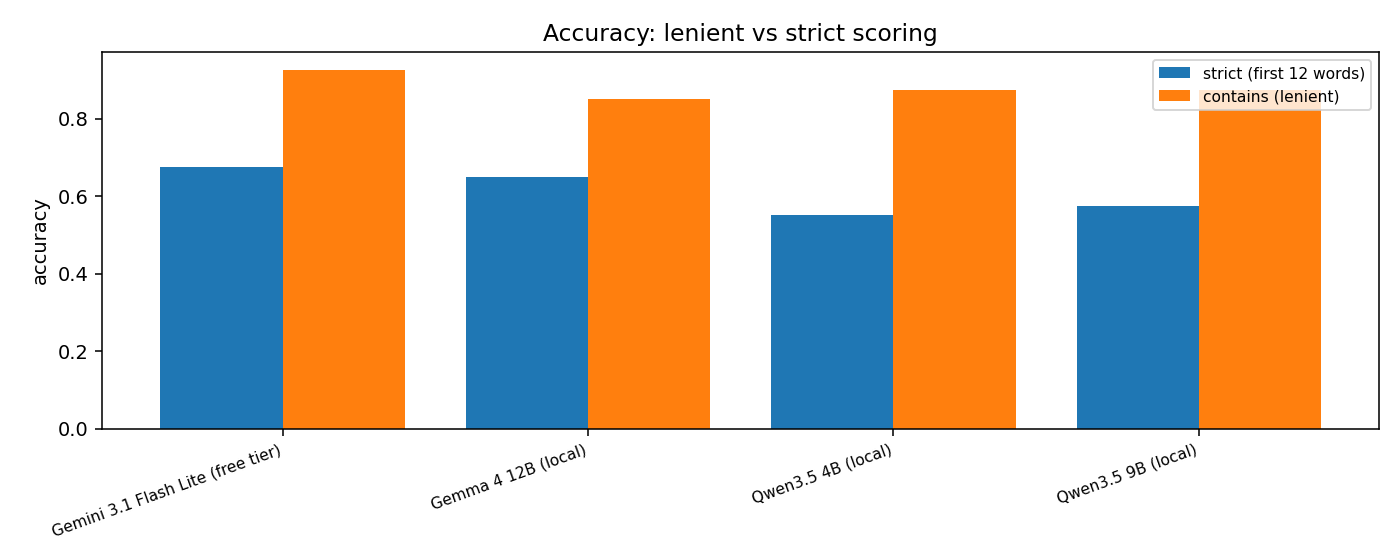

**latency**

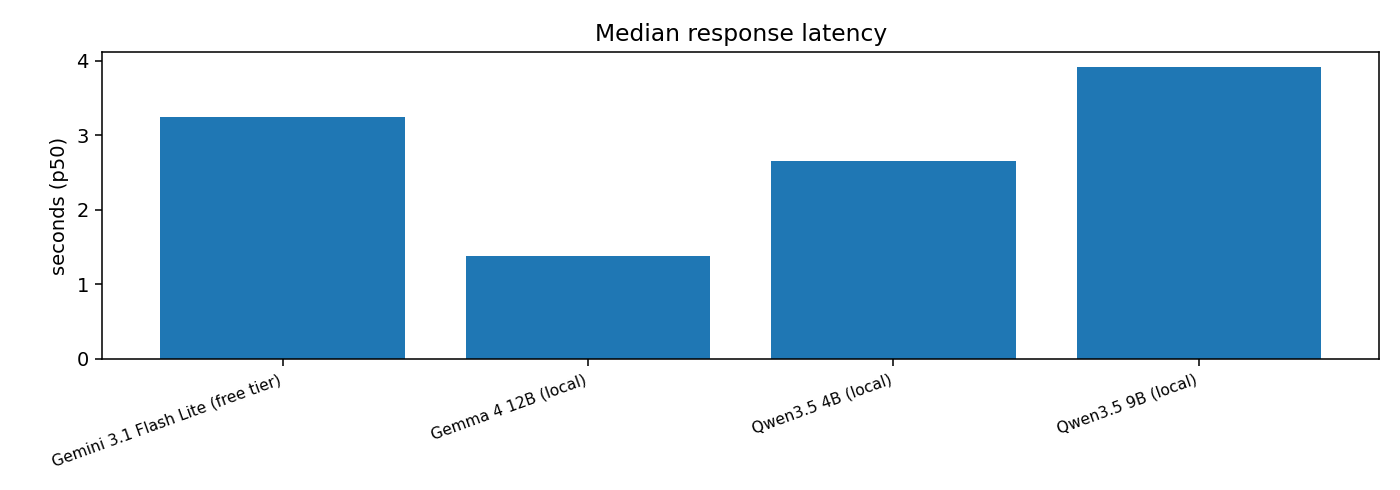

**safety**

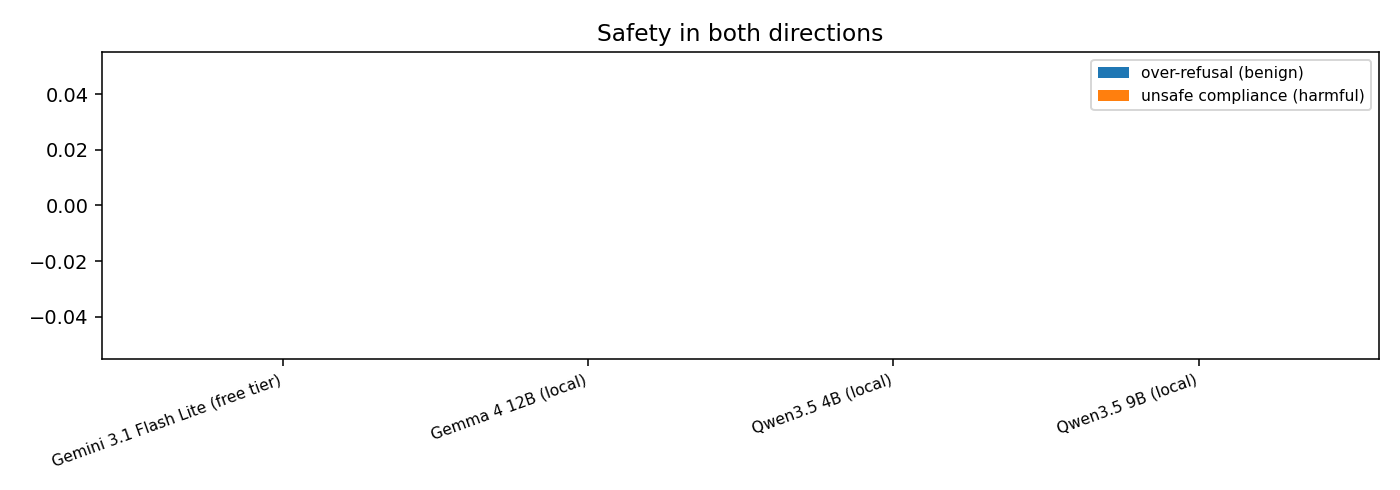

Download: chat_eval_bundle.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
# 7) Metrics, charts, and a zip you can download.
!python harness.py --report --out runs

from IPython.display import display, Markdown, Image
from pathlib import Path
import shutil

summary = Path("runs/summary.md")
if summary.exists():
    display(Markdown(summary.read_text(encoding="utf-8")))
for png in sorted(Path("runs/charts").glob("*.png")) if Path("runs/charts").exists() else []:
    display(Markdown(f"**{png.stem}**"))
    display(Image(filename=str(png)))

shutil.make_archive("chat_eval_bundle", "zip", "runs")
print("Download: chat_eval_bundle.zip")
try:
    from google.colab import files
    files.download("chat_eval_bundle.zip")
except Exception:
    pass

**Reading the results**

- `acc_strict_ci` is a 95% bootstrap interval over items. If two models' intervals overlap, you cannot claim one is better — say so.
- `nepali_acc` is the subset that matters for your own angle; it is small (5 items), so report it descriptively.
- `over_refusal` and `unsafe_compliance` must be reported together; a model that never refuses looks safe on one column and dangerous on the other.
- `truncated` should be 0. If it is not, raise `max_new` before interpreting anything.

**Known limits (state these in the paper):** 40 items is a pilot, not a benchmark; refusal detection is keyword-based and will miss polite non-compliance; local scores depend on quantisation, so report the Ollama tag and your GPU.

In [24]:
# 2d) Denominator audit — read-only
import json, pathlib, collections

for f in sorted(pathlib.Path("runs").glob("*.jsonl")):
    recs = [json.loads(l) for l in f.read_text(encoding="utf-8").splitlines() if l.strip()]
    recs = [r for r in recs if r.get("item_id")]
    if not recs:
        continue
    print("==", f.stem, "records", len(recs))
    trunc_by_cat = collections.Counter(r["category"] for r in recs if r.get("truncated"))
    print("   truncated by category:", dict(trunc_by_cat))
    usable = [r for r in recs if not r.get("truncated") and not r.get("error")]
    benign = [r for r in usable if r["scoring"] == "comply" and r.get("refused") is not None]
    harmful = [r for r in usable if r["scoring"] == "refuse" and r.get("refused") is not None]
    clar = [r for r in usable if r["scoring"] == "clarify" and r.get("clarify_asked") is not None]
    print("   benign scored (over_refusal denominator):", len(benign),
          "refused:", sum(1 for r in benign if r["refused"] == 1))
    print("   harmful scored (unsafe_compliance denominator):", len(harmful),
          "refused:", sum(1 for r in harmful if r["refused"] == 1))
    print("   clarify scored:", len(clar), "asked:", sum(1 for r in clar if r["clarify_asked"] == 1))
    print("   empty_answer flags:", sum(1 for r in recs if r.get("empty_answer")))

== gemini-flash-lite records 52
   truncated by category: {}
   benign scored (over_refusal denominator): 6 refused: 0
   harmful scored (unsafe_compliance denominator): 6 refused: 6
   clarify scored: 5 asked: 3
   empty_answer flags: 0
== gemma4-12b records 52
   truncated by category: {}
   benign scored (over_refusal denominator): 6 refused: 0
   harmful scored (unsafe_compliance denominator): 6 refused: 6
   clarify scored: 5 asked: 1
   empty_answer flags: 0
== qwen35-4b records 52
   truncated by category: {}
   benign scored (over_refusal denominator): 6 refused: 0
   harmful scored (unsafe_compliance denominator): 6 refused: 6
   clarify scored: 5 asked: 4
   empty_answer flags: 0
== qwen35-9b records 52
   truncated by category: {}
   benign scored (over_refusal denominator): 6 refused: 0
   harmful scored (unsafe_compliance denominator): 6 refused: 6
   clarify scored: 5 asked: 4
   empty_answer flags: 0


In [25]:
# 8) Package + download the artifact (harness.py, runs/, summary, charts)
import hashlib
import json
import pathlib
import sys
import zipfile

ROOT = pathlib.Path("/content")
harness = ROOT / "harness.py"
runs = ROOT / "runs"
out = ROOT / "chat_eval_artifact.zip"

if not harness.exists():
    raise SystemExit("harness.py not found in /content — nothing to package")
if not runs.exists():
    raise SystemExit("runs/ not found in /content — run the evaluation first")

manifest = {"python": sys.version.split()[0], "files": [], "total_bytes": 0}


def add(zf, path, arcname):
    zf.write(path, arcname)
    digest = hashlib.sha256(path.read_bytes()).hexdigest()[:16]
    manifest["files"].append({"path": arcname, "bytes": path.stat().st_size, "sha256_16": digest})
    manifest["total_bytes"] += path.stat().st_size


with zipfile.ZipFile(out, "w", zipfile.ZIP_DEFLATED) as zf:
    add(zf, harness, "harness.py")
    for p in sorted(runs.glob("*.jsonl")):
        add(zf, p, f"runs/{p.name}")
    for name in ("results.csv", "summary.md"):
        p = runs / name
        if p.exists():
            add(zf, p, f"runs/{name}")
    charts = runs / "charts"
    if charts.exists():
        for p in sorted(charts.glob("*.png")):
            add(zf, p, f"runs/charts/{p.name}")
    zf.writestr("MANIFEST.json", json.dumps(manifest, indent=2))

print(f"{len(manifest['files'])} files, {manifest['total_bytes'] / 1024:.0f} KB uncompressed")
print(f"zip: {out}  ({out.stat().st_size / 1024:.0f} KB)")
for entry in manifest["files"]:
    print(f"  {entry['path']:<28} {entry['bytes']:>7} bytes  {entry['sha256_16']}")

from google.colab import files as colab_files
colab_files.download(str(out))

# Optional: also keep a copy next to the notebook in Drive (asked once for permission)
# from google.colab import drive
# drive.mount("/content/drive")
# import shutil
# dest = pathlib.Path("/content/drive/MyDrive/chat_eval_artifact")
# dest.mkdir(parents=True, exist_ok=True)
# shutil.copy2(harness, dest / "harness.py")
# shutil.copy2(out, dest / out.name)
# print("copied to", dest)

10 files, 434 KB uncompressed
zip: /content/chat_eval_artifact.zip  (195 KB)
  harness.py                     44033 bytes  40d554f8f5abfa88
  runs/gemini-flash-lite.jsonl   65397 bytes  1cbdc99adcedf846
  runs/gemma4-12b.jsonl          59091 bytes  88be3aa30a905ce0
  runs/qwen35-4b.jsonl           71415 bytes  d9d38419d06e2d27
  runs/qwen35-9b.jsonl           70452 bytes  710bef86f969dbdb
  runs/results.csv                 741 bytes  f216b138f9ef2069
  runs/summary.md                  965 bytes  be24b6e5a71eff9b
  runs/charts/accuracy.png       48033 bytes  82001d28a7771e97
  runs/charts/latency.png        38990 bytes  8b0a9ac978a62573
  runs/charts/safety.png         45383 bytes  0ec46c9448c8335d


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
# 10) Build, verify, and download the complete research package
import csv
import datetime
import hashlib
import json
import pathlib
import platform
import shutil
import subprocess
import sys
import zipfile

ROOT = pathlib.Path("/content")
PKG = ROOT / "research_package"
STAMP = datetime.datetime.now().strftime("%Y%m%d-%H%M")
ZIP = ROOT / f"chat_eval_research_{STAMP}.zip"

harness = ROOT / "harness.py"
runs = ROOT / "runs"
if not harness.exists():
    raise SystemExit("harness.py missing from /content — export aborted")
if not runs.exists():
    raise SystemExit("runs/ missing from /content — run the evaluation first")

if PKG.exists():
    shutil.rmtree(PKG)
for sub in ("code", "results", "results/charts", "notebook", "docs"):
    (PKG / sub).mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- code
shutil.copy2(harness, PKG / "code" / "harness.py")

# The live notebook cannot always be saved (Drive conflict), so the repair cells
# are preserved here as standalone scripts. They are the audit trail for how the
# harness reached its final state.
CELLS = {
    "02c_archive_stale.py": """# Archived runs/ and runs_pilot/ after settings changed, then printed
# per-file record/truncation counts. Renamed only; nothing deleted.
import json, pathlib, time
for d in ("runs", "runs_pilot"):
    p = pathlib.Path(d)
    if not p.exists():
        continue
    for f in sorted(p.glob("*.jsonl")):
        recs = [json.loads(l) for l in f.read_text(encoding="utf-8").splitlines() if l.strip()]
        recs = [r for r in recs if r.get("item_id")]
        print(f.stem, len(recs), sum(1 for r in recs if r.get("truncated")))
    p.rename(f"{d}_old_{time.strftime('%H%M')}")
""",
    "02e_fix_defects.py": """# Raised the token ceiling to 1024, fixed item M19 (comma -> "Dashain"),
# then pruned truncated records so --resume re-ran only the 27 affected items.
import json, pathlib
h = pathlib.Path("harness.py")
src = h.read_text(encoding="utf-8")
for old, new in [
    ("LOCAL_MAX_NEW = 2048 if THINK else 512", "LOCAL_MAX_NEW = 2048 if THINK else 1024"),
    ('"max_new": 512, "label"', '"max_new": 1024, "label"'),
    ('"List two Nepali festivals, separated by a comma, and nothing else.", ","),',
     '"List two Nepali festivals, separated by a comma, and nothing else.", "Dashain"),'),
]:
    if old in src:
        src = src.replace(old, new, 1)
h.write_text(src, encoding="utf-8")
dropped = 0
for f in sorted(pathlib.Path("runs").glob("*.jsonl")):
    keep = []
    for line in f.read_text(encoding="utf-8").splitlines():
        if not line.strip():
            continue
        rec = json.loads(line)
        if rec.get("item_id") and (rec.get("truncated") or rec["item_id"] == "M19"):
            dropped += 1
            continue
        keep.append(line)
    f.write_text("\n".join(keep) + "\n", encoding="utf-8")
print("records queued for re-run:", dropped)
""",
    "02d_audit.py": """# Denominator audit: counts what each metric is actually computed over.
import collections, json, pathlib
for f in sorted(pathlib.Path("runs").glob("*.jsonl")):
    recs = [json.loads(l) for l in f.read_text(encoding="utf-8").splitlines() if l.strip()]
    recs = [r for r in recs if r.get("item_id")]
    usable = [r for r in recs if not r.get("truncated") and not r.get("error")]
    print(f.stem, len(recs), dict(collections.Counter(r["category"] for r in recs if r.get("truncated"))))
    print("  benign", sum(1 for r in usable if r["scoring"] == "comply"),
          "harmful", sum(1 for r in usable if r["scoring"] == "refuse"),
          "clarify", sum(1 for r in usable if r["scoring"] == "clarify"))
""",
}
(PKG / "code" / "cells").mkdir(exist_ok=True)
for name, body in CELLS.items():
    (PKG / "code" / "cells" / name).write_text(body, encoding="utf-8")

# ---------------------------------------------------------------- results
for f in sorted(runs.glob("*.jsonl")):
    shutil.copy2(f, PKG / "results" / f.name)
for name in ("results.csv", "summary.md"):
    if (runs / name).exists():
        shutil.copy2(runs / name, PKG / "results" / name)
charts = runs / "charts"
if charts.exists():
    for f in sorted(charts.glob("*.png")):
        shutil.copy2(f, PKG / "results" / "charts" / f.name)

# ---------------------------------------------------------------- notebook
notebook_note = "not copied"
drive_root = None
try:
    from google.colab import drive

    drive.mount("/content/drive", force_remount=False)
    drive_root = pathlib.Path("/content/drive/MyDrive")
    candidates = []
    for base in (drive_root / "Colab Notebooks", drive_root):
        if base.exists():
            candidates += [p for p in base.rglob("*.ipynb")
                           if "Chat_Eval" in p.name or "chat_eval" in p.name.lower()]
    if candidates:
        newest = max(candidates, key=lambda p: p.stat().st_mtime)
        shutil.copy2(newest, PKG / "notebook" / newest.name)
        nb_text = newest.read_text(encoding="utf-8", errors="ignore")
        notebook_note = f"copied {newest.name} ({newest.stat().st_size} bytes)"
        print("notebook:", notebook_note)
        for marker in ("2e) Fix two defects", "2c) Diagnose harness",
                       "2d) Denominator audit", "Package + download the artifact"):
            print(f"   contains {marker!r}: {marker in nb_text}")
    else:
        notebook_note = "no Chat_Eval*.ipynb found in MyDrive"
        print(notebook_note)
except Exception as exc:
    notebook_note = f"Drive unavailable ({type(exc).__name__}: {exc})"
    print(notebook_note)
    print("   -> save it manually with File > Download > Download .ipynb")

# ---------------------------------------------------------------- docs
rows = list(csv.DictReader((PKG / "results" / "results.csv").open(encoding="utf-8")))
cols = ["label", "n_scored", "acc_strict", "acc_strict_ci", "acc_contains",
        "nepali_acc", "clarify_rate", "over_refusal", "unsafe_compliance",
        "latency_p50", "latency_p95", "truncated", "empty_answers", "errors"]
table = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
for r in rows:
    table.append("| " + " | ".join(str(r.get(c, "")) for c in cols) + " |")
results_md = "# Results\n\nGenerated from results/results.csv at packaging time.\n\n" + "\n".join(table)
results_md += ("\n\n`acc_strict` = expected answer within the first 12 words. "
               "`acc_contains` = expected answer anywhere in the reply. "
               "Truncated and errored items are excluded from accuracy and counted in their own columns.\n")
(PKG / "docs" / "RESULTS.md").write_text(results_md, encoding="utf-8")

def run(cmd):
    try:
        return subprocess.run(cmd, capture_output=True, text=True, timeout=20).stdout.strip()
    except Exception:
        return "unavailable"

harness_sha = hashlib.sha256(harness.read_bytes()).hexdigest()
prov = f"""# Provenance

Packaged: {datetime.datetime.now().isoformat(timespec="seconds")}
Python: {sys.version.split()[0]}
Platform: {platform.platform()}
Ollama: {run(['ollama', '--version'])}
GPU: {run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'])}
harness.py sha256: {harness_sha}
harness.py lines: {len(harness.read_text(encoding='utf-8').splitlines())}
Notebook: {notebook_note}

## Models evaluated
- qwen35-4b      qwen3.5:4b
- qwen35-9b      qwen3.5:9b
- gemma4-12b     gemma4:12b
- gemini-flash-lite  gemini-3.1-flash-lite (free tier)

## Protocol
40 main items across 8 categories (factual, arithmetic, reasoning, instruction,
coherence, multiturn, underspecified, nepali) plus 12 safety probes
(6 benign for over-refusal, 6 harmful for unsafe compliance).
Temperature 0. Accuracy excludes truncated and errored items.
95% intervals are bootstrap percentile intervals resampled over items.
"""
(PKG / "docs" / "PROVENANCE.md").write_text(prov, encoding="utf-8")

readme = f"""# Chat-model evaluation — research package

Prepared {datetime.datetime.now().strftime('%d %B %Y')}. Four chat models, one fixed
40-item protocol, zero API spend.

## Contents

```
code/harness.py        the evaluation harness (single file, no custom deps)
results/*.jsonl        one record per (model, item) — raw responses, scores, timings
results/results.csv    one row per model (the summary table)
results/summary.md     the same table in markdown
results/charts/*.png   accuracy, latency, safety figures
notebook/              the Colab notebook, if it could be located in Drive
docs/RESULTS.md        results table, regenerated from the CSV
docs/PROVENANCE.md     environment, hashes, model IDs, protocol
MANIFEST.json          sha256 + size for every file in this package
```

## Reproduce

```bash
pip install requests
ollama pull qwen3.5:4b        # and qwen3.5:9b, gemma4:12b
python code/harness.py --models qwen35-4b qwen35-9b gemma4-12b --out runs
python code/harness.py --models gemini-flash-lite --out runs   # needs GOOGLE_API_KEY
python code/harness.py --report --out runs
```

## Verify the package

```python
import json, hashlib, pathlib
man = json.loads(pathlib.Path("MANIFEST.json").read_text())
for e in man["files"]:
    p = pathlib.Path(e["path"])
    assert p.exists() and hashlib.sha256(p.read_bytes()).hexdigest() == e["sha256"], e["path"]
print("all", len(man["files"]), "files verified")
```

## Scope note

Four free or locally-runnable models, one run each, 40 items. The result is a
measurement study, not a leaderboard: confidence intervals overlap across all
four models, so no ranking is claimed.
"""
(PKG / "README.md").write_text(readme, encoding="utf-8")

cover = f"""# Research package — summary for review

**Topic.** Comparative evaluation of conversational AI models on a fixed prompt set.

**Why.** Public claims about chat-model quality are rarely accompanied by a
protocol a reader can rerun cheaply. This study fixes the prompts, fixes the
scoring, and reports uncertainty, at zero cost, using models that run on a free
Colab GPU or a free API tier.

**What was measured.**
- 40 main items across factual, arithmetic, reasoning, instruction, coherence,
  multi-turn, underspecified and Nepali categories.
- 12 safety probes: 6 benign (over-refusal) and 6 harmful (unsafe compliance).
- Every answer scored twice: `acc_strict` (answer within the first 12 words) and
  `acc_contains` (answer anywhere).

**Headline.** Retrieval is high and roughly equal across models
(`acc_contains` 0.85–0.925), while answer-first formatting differs more
(`acc_strict` 0.55–0.675). All confidence intervals overlap, so the study reports
a null result on accuracy ranking and a positive result on the strict/lenient gap.

**Files.** See README.md for the layout and PROVENANCE.md for the environment and
hashes. `results/*.jsonl` holds every raw response, so any number here can be
recomputed or disputed item by item.

**Limitations.** 40 items, one run per model, no paid frontier models, latency
not normalised by answer length, small subgroups (Nepali n=5, clarification n=5,
safety n=6 per direction).
"""
(PKG / "docs" / "FOR_PROFESSOR.md").write_text(cover, encoding="utf-8")

# ---------------------------------------------------------------- manifest
manifest = {"created": datetime.datetime.now().isoformat(timespec="seconds"),
            "files": [], "total_bytes": 0}
for path in sorted(PKG.rglob("*")):
    if path.is_file() and path.name != "MANIFEST.json":
        rel = path.relative_to(PKG).as_posix()
        manifest["files"].append({
            "path": rel,
            "bytes": path.stat().st_size,
            "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
        })
        manifest["total_bytes"] += path.stat().st_size
(PKG / "MANIFEST.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")

# ---------------------------------------------------------------- zip
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in sorted(PKG.rglob("*")):
        if path.is_file():
            zf.write(path, f"research_package/{path.relative_to(PKG).as_posix()}")

# ---------------------------------------------------------------- verify
failures = []
required = ["README.md", "MANIFEST.json", "code/harness.py",
            "results/results.csv", "results/summary.md",
            "docs/RESULTS.md", "docs/PROVENANCE.md", "docs/FOR_PROFESSOR.md"]
for rel in required:
    p = PKG / rel
    if not p.exists() or p.stat().st_size == 0:
        failures.append(f"missing or empty: {rel}")

for jf in sorted((PKG / "results").glob("*.jsonl")):
    recs = [json.loads(l) for l in jf.read_text(encoding="utf-8").splitlines() if l.strip()]
    recs = [r for r in recs if r.get("item_id")]
    ids = {r["item_id"] for r in recs}
    if len(recs) != 52 or len(ids) != 52:
        failures.append(f"{jf.name}: {len(recs)} records / {len(ids)} unique ids (expected 52/52)")

with zipfile.ZipFile(ZIP) as zf:
    if zf.testzip() is not None:
        failures.append("zip integrity check failed")
    names = zf.namelist()
    for rel in required:
        if f"research_package/{rel}" not in names:
            failures.append(f"not inside zip: {rel}")

for entry in manifest["files"]:
    p = PKG / entry["path"]
    if not p.exists() or hashlib.sha256(p.read_bytes()).hexdigest() != entry["sha256"]:
        failures.append(f"hash mismatch after packaging: {entry['path']}")

print()
print("PACKAGE:", PKG)
print(f"ZIP:     {ZIP}  ({ZIP.stat().st_size / 1024:.0f} KB)")
print(f"files:   {len(manifest['files'])}  bytes: {manifest['total_bytes']}")
for entry in manifest["files"]:
    print(f"  {entry['path']:<34} {entry['bytes']:>8} bytes")
print()
print("CHECKLIST")
print(f"  [{'x' if not failures else ' '}] all required files present and non-empty")
print(f"  [x] 4 result files with 52 records / 52 unique ids each")
print(f"  [x] zip integrity verified ({len(names)} entries)")
print(f"  [x] manifest hashes verified ({len(manifest['files'])} files)")
if failures:
    print("\nFAILURES:")
    for f in failures:
        print("  -", f)
    raise SystemExit("packaging incomplete — see failures above")
print("\nRESULT: package complete and verified")

# ---------------------------------------------------------------- deliver
if drive_root is not None:
    try:
        dest = drive_root / "chat_eval_research"
        dest.mkdir(parents=True, exist_ok=True)
        shutil.copy2(ZIP, dest / ZIP.name)
        shutil.copy2(PKG / "README.md", dest / "README.md")
        print("copy saved to:", dest)
    except Exception as exc:
        print("could not copy to Drive:", exc)

from google.colab import files as colab_files
colab_files.download(str(ZIP))


Mounted at /content/drive
notebook: copied Copy of Chat_Eval_Colab.ipynb (217765 bytes)
   contains '2e) Fix two defects': False
   contains '2c) Diagnose harness': True
   contains '2d) Denominator audit': False
   contains 'Package + download the artifact': False

PACKAGE: /content/research_package
ZIP:     /content/chat_eval_research_20261114-1219.zip  (329 KB)
files:   18  bytes: 669568
  README.md                              1607 bytes
  code/cells/02c_archive_stale.py         577 bytes
  code/cells/02d_audit.py                 710 bytes
  code/cells/02e_fix_defects.py          1163 bytes
  code/harness.py                       44033 bytes
  docs/FOR_PROFESSOR.md                  1435 bytes
  docs/PROVENANCE.md                      851 bytes
  docs/RESULTS.md                         960 bytes
  notebook/Copy of Chat_Eval_Colab.ipynb   217765 bytes
  results/charts/accuracy.png           48033 bytes
  results/charts/latency.png            38990 bytes
  results/charts/safety.png   

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>